In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 14

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

data = pd.read_csv("../data/raw/train.csv")

data["date"] = pd.to_datetime(data["date"])

data = data.sort_values(
    ["date", "store", "item"]
).reset_index(drop=True)

print("Dataset loaded successfully!")
print("Shape:", data.shape)
display(data.head())


Dataset loaded successfully!
Shape: (913000, 4)


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-01,1,2,33
2,2013-01-01,1,3,15
3,2013-01-01,1,4,10
4,2013-01-01,1,5,11


# total sales on given day across all shops


In [3]:

daily_sales = (
    data.groupby("date")["sales"]
    .sum()
    .reset_index()
)

daily_sales = daily_sales.sort_values("date")

display(daily_sales.head())

print("Total daily observations:", len(daily_sales))
print("Average daily sales:", daily_sales["sales"].mean())


,date,sales
0,2013-01-01,13696
1,2013-01-02,13678
2,2013-01-03,14488
3,2013-01-04,15677
4,2013-01-05,16237


Total daily observations: 1826
Average daily sales: 26125.143483023003


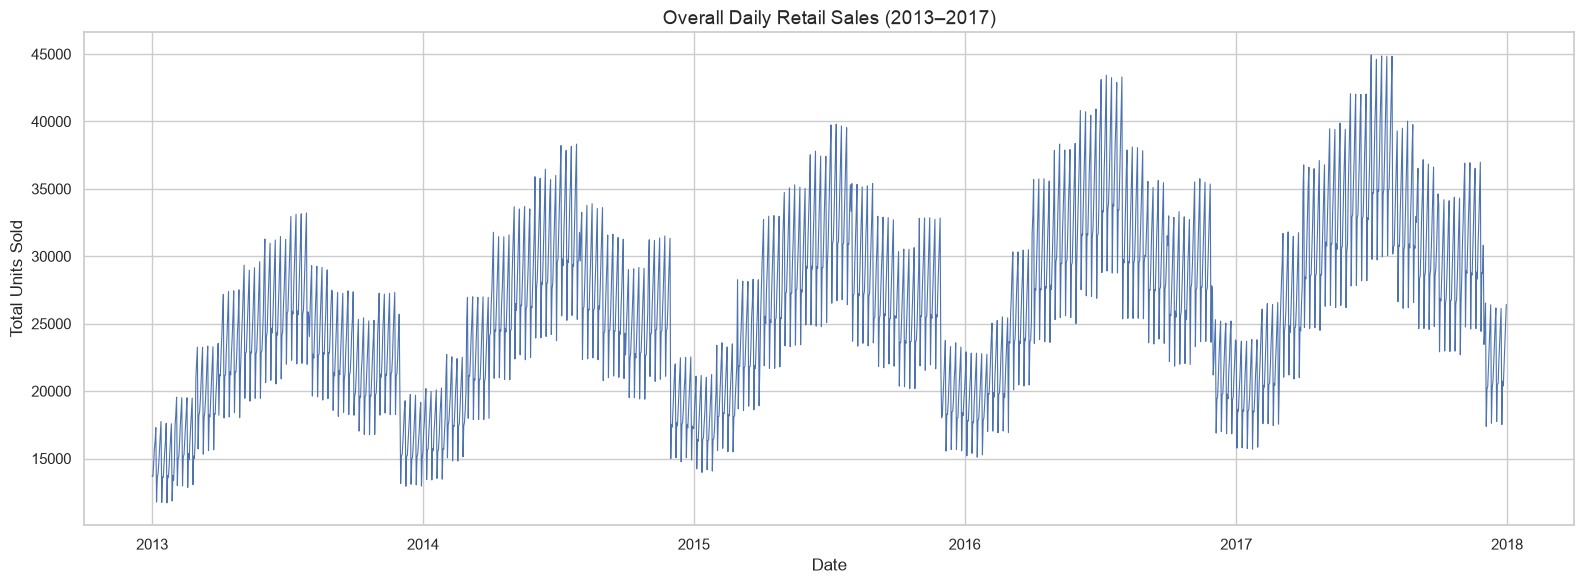

In [4]:

plt.figure(figsize=(16, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["sales"],
    linewidth=0.8
)

plt.title("Overall Daily Retail Sales (2013–2017)")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.tight_layout()
plt.show()


Monthly sales aggregation
total salaes for each month

,date,sales
0,2013-01-31,454904
1,2013-02-28,459417
2,2013-03-31,617382
3,2013-04-30,682274
4,2013-05-31,763242


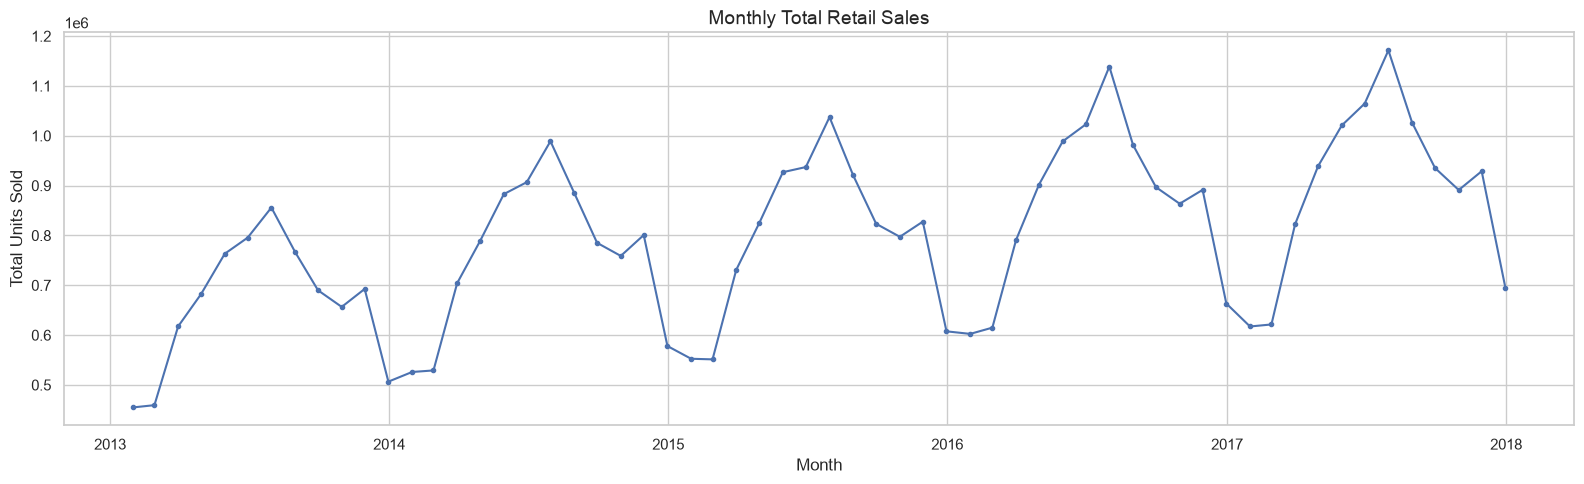

In [5]:

monthly_sales = (
    daily_sales.set_index("date")["sales"]
    .resample("ME")
    .sum()
    .reset_index()
)

display(monthly_sales.head())

plt.figure(figsize=(16, 5))

plt.plot(
    monthly_sales["date"],
    monthly_sales["sales"],
    marker="o",
    markersize=3
)

plt.title("Monthly Total Retail Sales")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")
plt.tight_layout()
plt.show()


Yearly sales comparison

,year,total_sales
0,2013,7941243
1,2014,9135482
2,2015,9536887
3,2016,10357160
4,2017,10733740


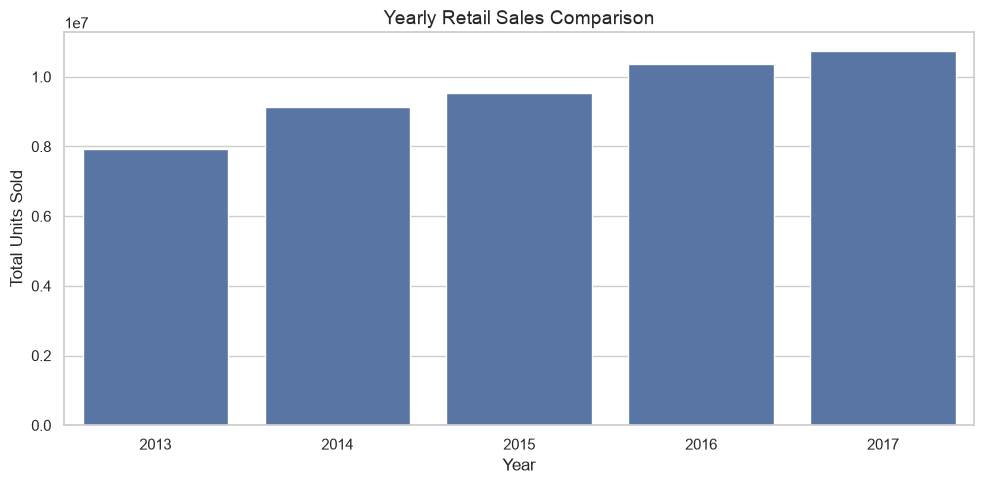

In [6]:

yearly_sales = (
    daily_sales.groupby(daily_sales["date"].dt.year)["sales"]
    .sum()
    .reset_index()
)

yearly_sales.columns = ["year", "total_sales"]

display(yearly_sales)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=yearly_sales,
    x="year",
    y="total_sales"
)

plt.title("Yearly Retail Sales Comparison")
plt.xlabel("Year")
plt.ylabel("Total Units Sold")
plt.tight_layout()
plt.show()


Cell 7 — Day-of-week analysis
Do customers purchase more on weekends or weekdays?

/var/folders/ft/nmfw_x454xgck71zjyx6w1m40000gn/T/ipykernel_45794/2741391792.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  daily_sales["day_number"] = daily_sales["date"].dt.dayofweek


,day_number,day_name,sales
0,0,Monday,20714.819231
1,1,Tuesday,24112.954023
2,2,Wednesday,24184.252874
3,3,Thursday,25861.609195
4,4,Friday,27578.624521
5,5,Saturday,29331.348659
6,6,Sunday,31071.666667


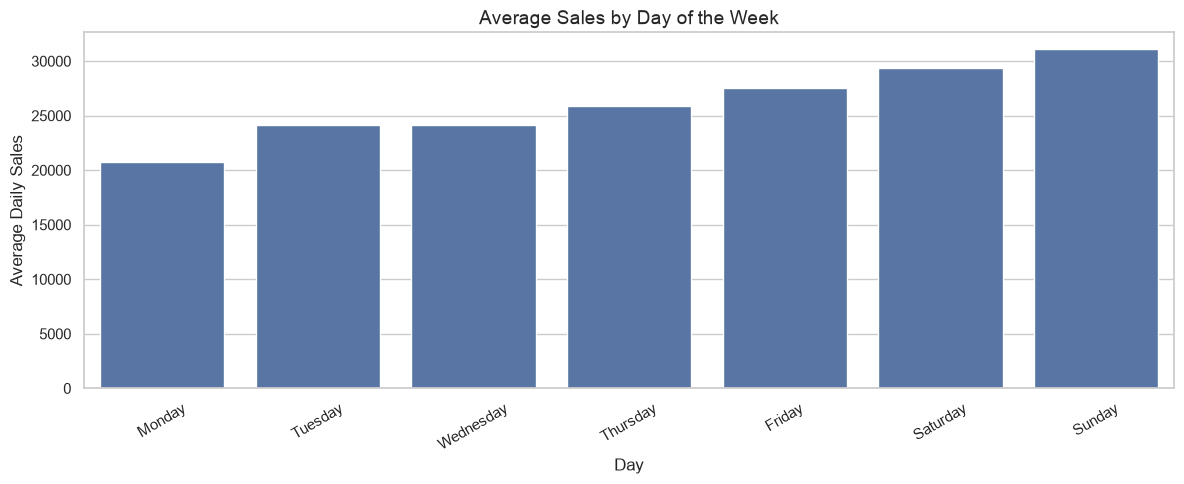

In [7]:

daily_sales["day_name"] = daily_sales["date"].dt.day_name()
daily_sales["day_number"] = daily_sales["date"].dt.dayofweek

weekday_sales = (
    daily_sales.groupby(["day_number", "day_name"])["sales"]
    .mean()
    .reset_index()
    .sort_values("day_number")
)

display(weekday_sales)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=weekday_sales,
    x="day_name",
    y="sales"
)

plt.title("Average Sales by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Average Daily Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


Monthly seasonality
Let's investigate whether some months consistently generate higher sales.

,month,sales,month_name
0,1,17762.251613,Jan
1,2,19689.198582,Feb
2,3,23652.787097,Mar
3,4,27576.446667,Apr
4,5,29564.109677,May
5,6,31512.740000,Jun
6,7,33499.309677,Jul
7,8,29552.612903,Aug
8,9,27536.380000,Sep
9,10,25596.903226,Oct


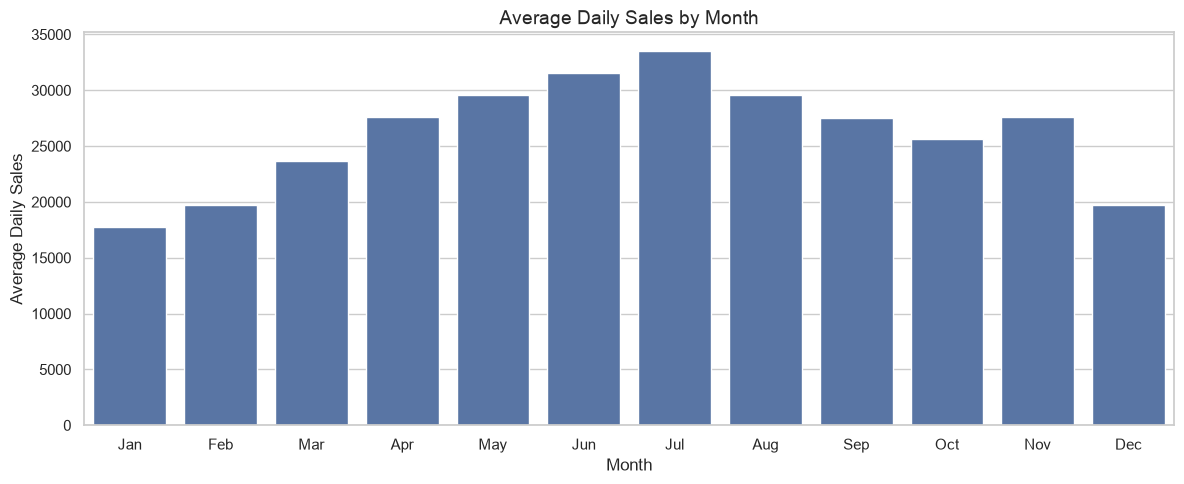

In [8]:

daily_sales["month"] = daily_sales["date"].dt.month

monthly_seasonality = (
    daily_sales.groupby("month")["sales"]
    .mean()
    .reset_index()
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_seasonality["month_name"] = (
    monthly_seasonality["month"].map(
        lambda month_number: month_names[month_number - 1]
    )
)

display(monthly_seasonality)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_seasonality,
    x="month_name",
    y="sales"
)

plt.title("Average Daily Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")
plt.tight_layout()
plt.show()


Cell 10 — Store-wise sales analysis

,store,sales
1,2,6120128
7,8,5856169
2,3,5435144
9,10,5360158
8,9,5025976
3,4,5012639
0,1,4315603
4,5,3631016
5,6,3627670
6,7,3320009


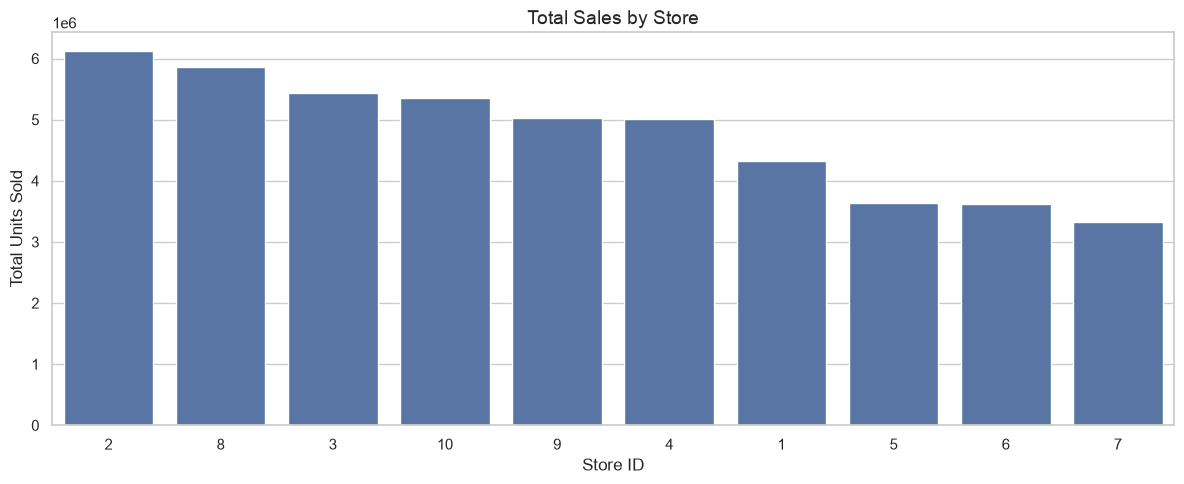

In [9]:

store_sales = (
    data.groupby("store")["sales"]
    .sum()
    .reset_index()
    .sort_values("sales", ascending=False)
)

display(store_sales)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=store_sales,
    x="store",
    y="sales",
    order=store_sales["store"]
)

plt.title("Total Sales by Store")
plt.xlabel("Store ID")
plt.ylabel("Total Units Sold")
plt.tight_layout()
plt.show()


Cell 11 — Product-wise sales analysis

,item,sales
14,15,1607442
27,28,1604713
12,13,1539621
17,18,1538876
24,25,1473334
44,45,1471467
37,38,1470330
21,22,1469971
35,36,1406548
7,8,1405108


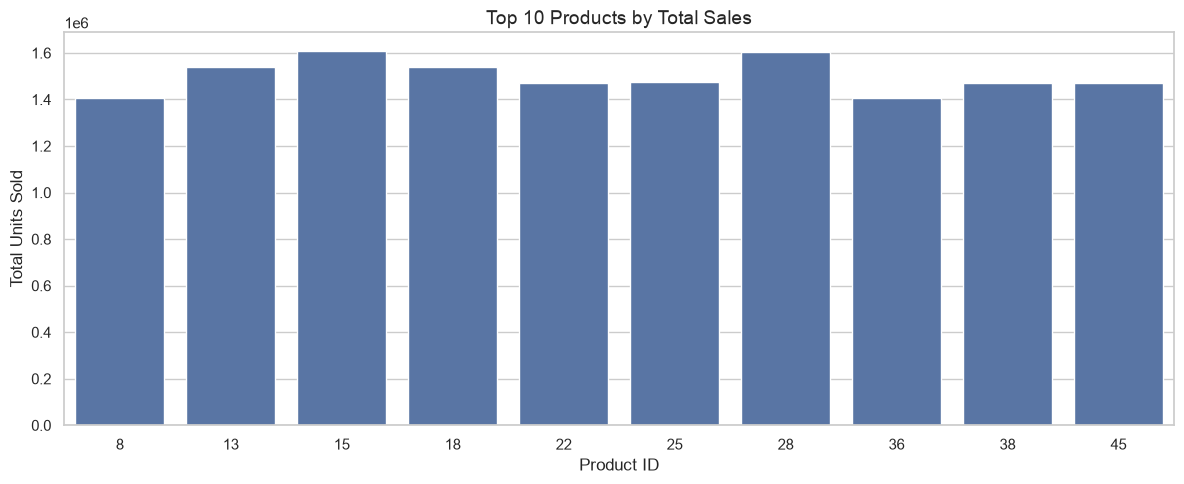

In [10]:

product_sales = (
    data.groupby("item")["sales"]
    .sum()
    .reset_index()
    .sort_values("sales", ascending=False)
)

display(product_sales.head(10))

plt.figure(figsize=(12, 5))

top_products = product_sales.head(10)

sns.barplot(
    data=top_products,
    x="item",
    y="sales"
)

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Product ID")
plt.ylabel("Total Units Sold")
plt.tight_layout()
plt.show()


Cell 12 — Sales distribution

Skewness: 0.21706498533802285
Kurtosis: -0.4535939002258791


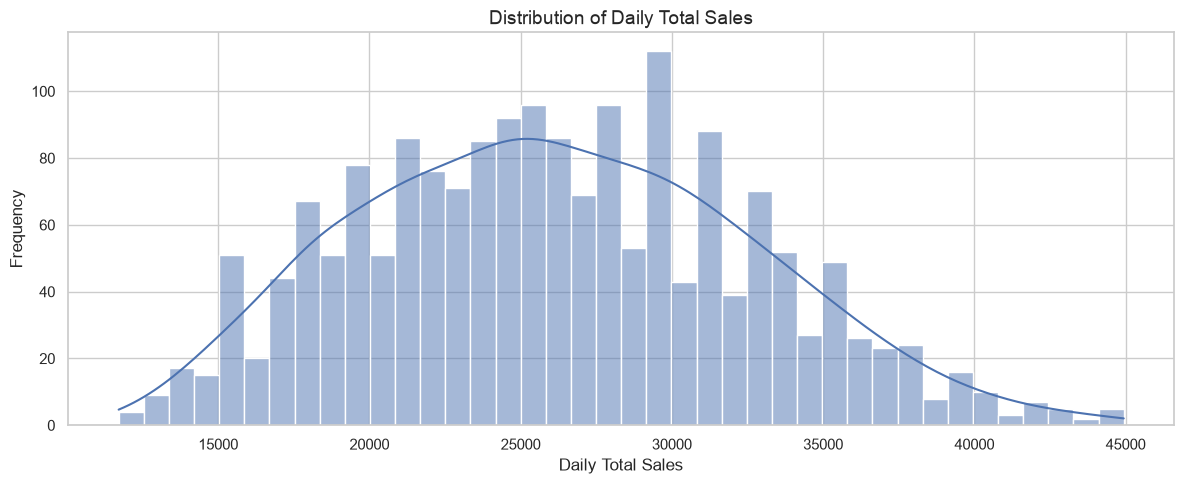

In [11]:

print("Skewness:", daily_sales["sales"].skew())
print("Kurtosis:", daily_sales["sales"].kurtosis())

plt.figure(figsize=(12, 5))

sns.histplot(
    daily_sales["sales"],
    bins=40,
    kde=True
)

plt.title("Distribution of Daily Total Sales")
plt.xlabel("Daily Total Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


Cell 13 — Boxplot and outlier investigation

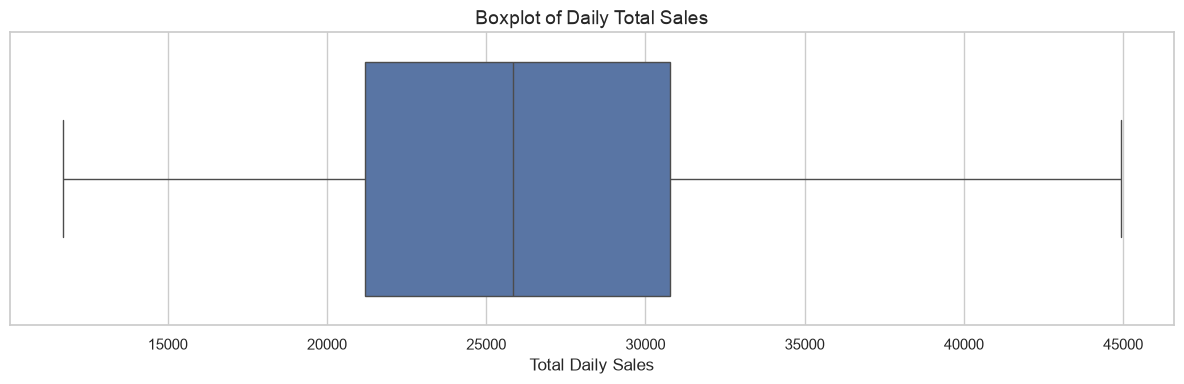

In [12]:

plt.figure(figsize=(12, 4))

sns.boxplot(x=daily_sales["sales"])

plt.title("Boxplot of Daily Total Sales")
plt.xlabel("Total Daily Sales")
plt.tight_layout()
plt.show()


Cell 14 — Identify potential outliers using IQR

In [13]:

first_quartile = daily_sales["sales"].quantile(0.25)
third_quartile = daily_sales["sales"].quantile(0.75)

interquartile_range = third_quartile - first_quartile

lower_bound = first_quartile - 1.5 * interquartile_range
upper_bound = third_quartile + 1.5 * interquartile_range

potential_outliers = daily_sales[
    (daily_sales["sales"] < lower_bound) |
    (daily_sales["sales"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outlier count:", len(potential_outliers))

display(potential_outliers.head(10))


Lower bound: 6818.25
Upper bound: 45156.25
Potential outlier count: 0


,date,sales,day_name,day_number,month


Cell 15 — Rolling mean and rolling standard deviation

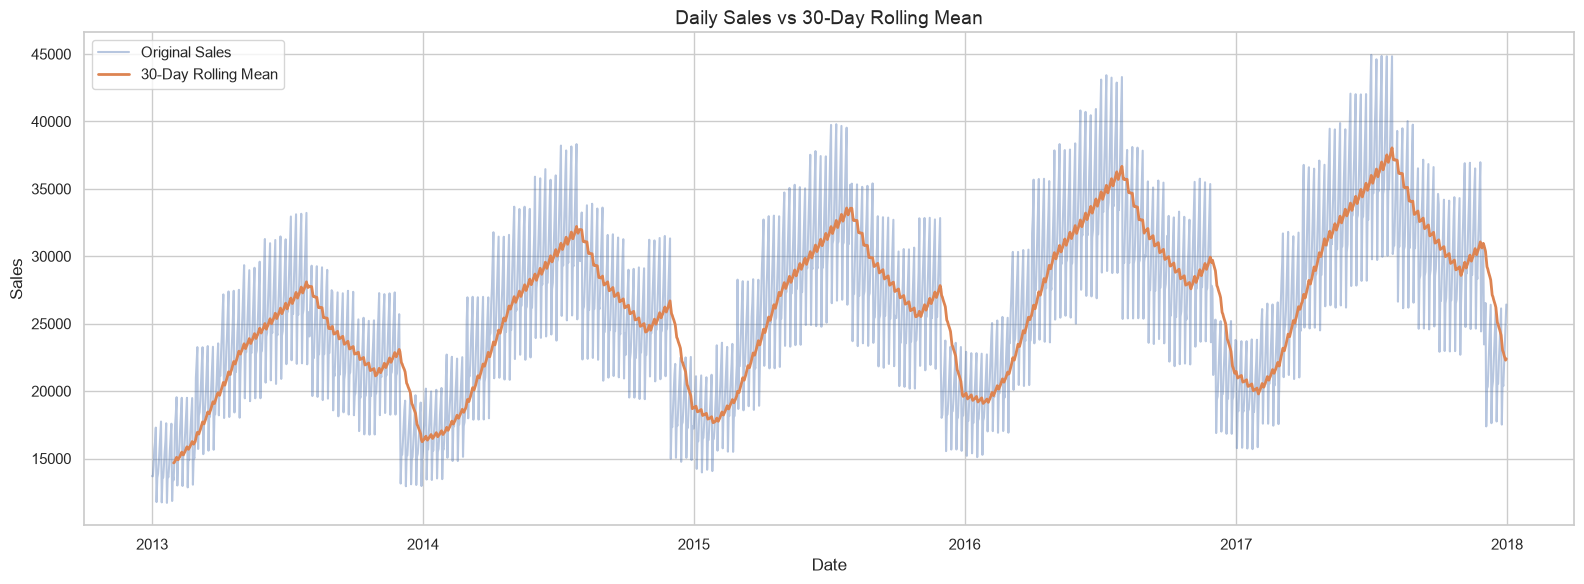

In [14]:

daily_sales["rolling_mean_30"] = (
    daily_sales["sales"].rolling(window=30).mean()
)

daily_sales["rolling_std_30"] = (
    daily_sales["sales"].rolling(window=30).std()
)

plt.figure(figsize=(16, 6))

plt.plot(
    daily_sales["date"],
    daily_sales["sales"],
    label="Original Sales",
    alpha=0.4
)

plt.plot(
    daily_sales["date"],
    daily_sales["rolling_mean_30"],
    label="30-Day Rolling Mean",
    linewidth=2
)

plt.title("Daily Sales vs 30-Day Rolling Mean")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()


Cell 16 — Rolling standard deviation

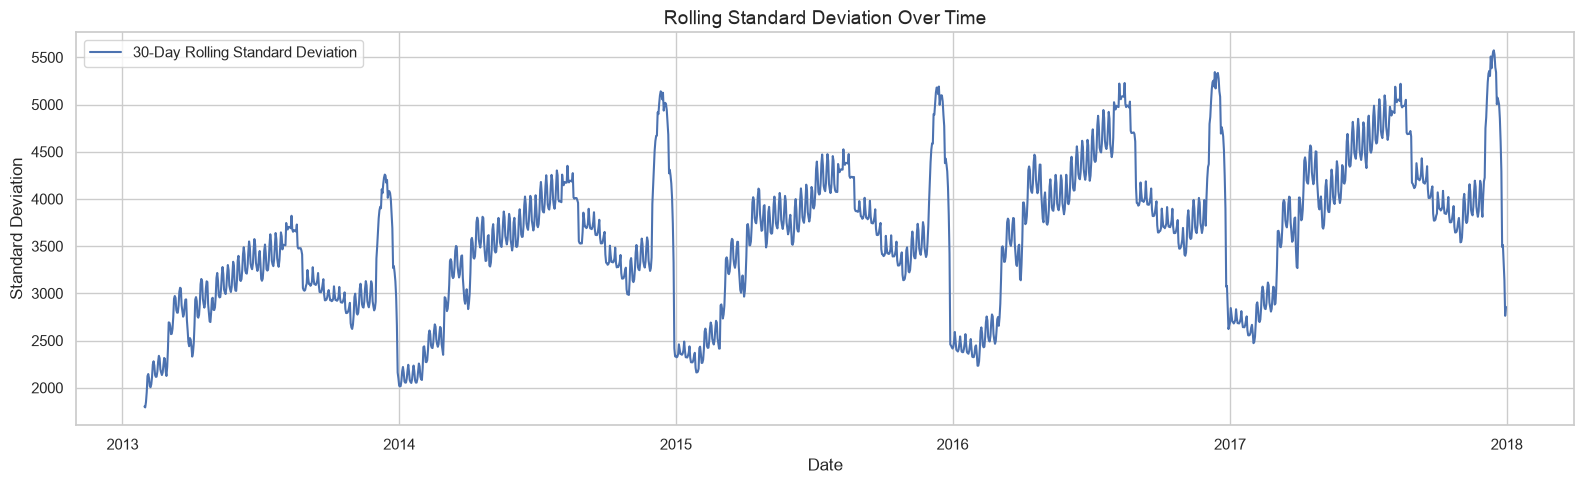

In [15]:

plt.figure(figsize=(16, 5))

plt.plot(
    daily_sales["date"],
    daily_sales["rolling_std_30"],
    label="30-Day Rolling Standard Deviation"
)

plt.title("Rolling Standard Deviation Over Time")
plt.xlabel("Date")
plt.ylabel("Standard Deviation")
plt.legend()
plt.tight_layout()
plt.show()


Cell 17 — Weekly aggregation

,date,sales
0,2013-01-06,91067
1,2013-01-13,103902
2,2013-01-20,102950
3,2013-01-27,103298
4,2013-02-03,109027


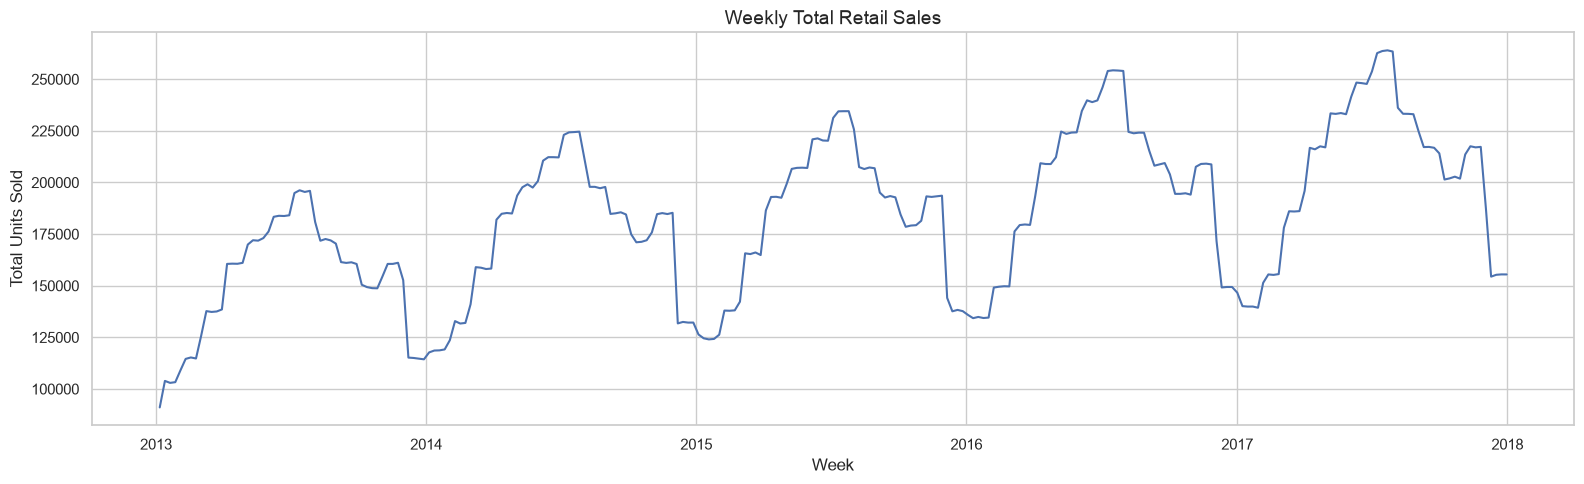

In [16]:

weekly_sales = (
    daily_sales.set_index("date")["sales"]
    .resample("W")
    .sum()
    .reset_index()
)

display(weekly_sales.head())

plt.figure(figsize=(16, 5))

plt.plot(
    weekly_sales["date"],
    weekly_sales["sales"]
)

plt.title("Weekly Total Retail Sales")
plt.xlabel("Week")
plt.ylabel("Total Units Sold")
plt.tight_layout()
plt.show()


Cell 18 — Monthly sales heatmap by year

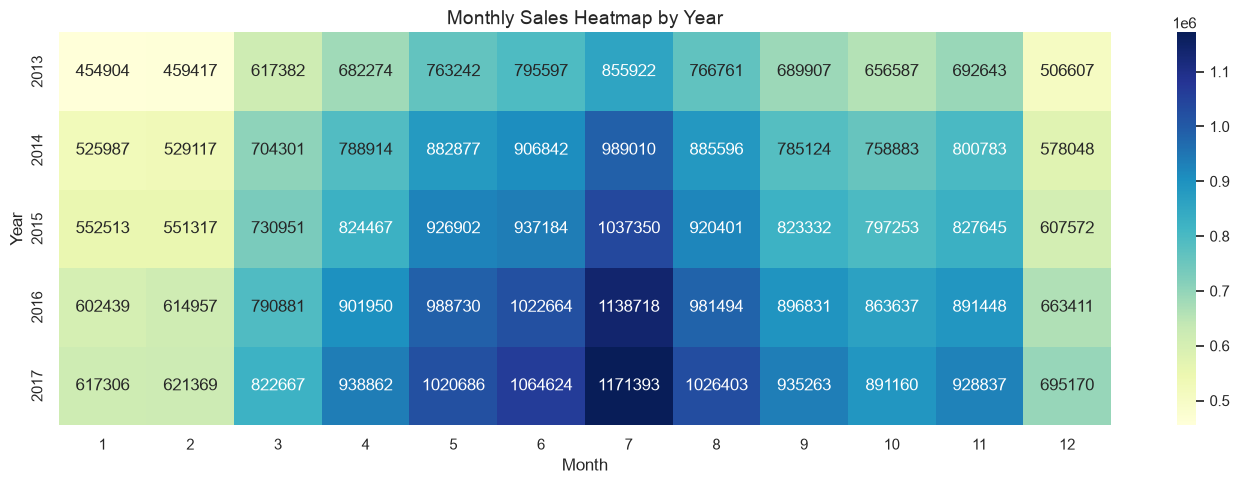

In [17]:

monthly_sales["year"] = monthly_sales["date"].dt.year
monthly_sales["month"] = monthly_sales["date"].dt.month

monthly_heatmap_data = monthly_sales.pivot(
    index="year",
    columns="month",
    values="sales"
)

plt.figure(figsize=(14, 5))

sns.heatmap(
    monthly_heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Monthly Sales Heatmap by Year")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()


Cell 19 — Automatic EDA summary

In [18]:

print("========== RETAIL SALES EDA SUMMARY ==========")

print("Total daily observations:", len(daily_sales))

print(
    "Average daily sales:",
    round(daily_sales["sales"].mean(), 2)
)

print(
    "Median daily sales:",
    round(daily_sales["sales"].median(), 2)
)

print(
    "Minimum daily sales:",
    daily_sales["sales"].min()
)

print(
    "Maximum daily sales:",
    daily_sales["sales"].max()
)

print(
    "Daily sales standard deviation:",
    round(daily_sales["sales"].std(), 2)
)

print(
    "Most profitable sales weekday (by average volume):",
    weekday_sales.loc[
        weekday_sales["sales"].idxmax(), "day_name"
    ]
)

print(
    "Highest average sales month:",
    monthly_seasonality.loc[
        monthly_seasonality["sales"].idxmax(), "month_name"
    ]
)

print(
    "Highest selling store:",
    int(store_sales.iloc[0]["store"])
)

print(
    "Highest selling product:",
    int(product_sales.iloc[0]["item"])
)

print("===============================================")


========== RETAIL SALES EDA SUMMARY ==========
Total daily observations: 1826
Average daily sales: 26125.14
Median daily sales: 25839.5
Minimum daily sales: 11709
Maximum daily sales: 44936
Daily sales standard deviation: 6418.27
Most profitable sales weekday (by average volume): Sunday
Highest average sales month: Jul
Highest selling store: 2
Highest selling product: 15



# EDA Findings and Business Insights

1. The business shows an overall upward sales trend.
2. Sunday has the highest average daily sales.
3. Monday has the lowest average daily sales.
4. July has the highest average daily sales among months.
5. Store 2 has the highest total sales.
6. Product 15 has the highest total sales.
7. The sales distribution has relatively low positive skewness.
8. No observations were identified as outliers using the 1.5 × IQR rule.

## Initial Time-Series Observations

- Long-term upward trend is suspected.
- Weekly seasonality is suspected.
- Annual seasonality is suspected.
- Further statistical analysis is required to establish stationarity and seasonal structure.

## Next Steps

Perform classical decomposition and STL decomposition to separate trend, seasonal and residual components.
